In [2]:
!python3 --version

Python 3.8.10


In [3]:
import numpy as np
import torch
from model import process_and_segment_image
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import backend as K
from matplotlib import pyplot as plt
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets
from deepcell.applications import CytoplasmSegmentation
from deepcell.datasets.cytoplasm import hela_s3
import warnings
from skimage.segmentation import relabel_sequential
from deepcell.applications import CellTracking
from random import sample
import json
import sys
import zipfile
from io import BytesIO
import tifffile
import sys
import pandas as pd
import json
import cv2
import skimage.exposure as skie

sys.path.append('../data-registry/cli/')
from data_utils import DclOutputWriter
from data_utils import load_data_local,dcl_to_binary_mask
from iou_tracking_dcl import find_boundary_box

In [4]:
# The model weights are a .pth file. We have copies on magik and northstar. Reach out to Uriah or Rohit for the path.
model_weight_path = "./.cellsam_assets/mixed_model_inference_balanced.pth"
model = torch.load(model_weight_path, map_location=torch.device("cpu"))

# These are reasonable defaults, but set these as needed for your application
model.bbox_threshold = 0.4/1.05
model.mask_threshold = 0.4/5.05
model.iou_threshold = 0.5/1.05
model = model.eval().cuda()

/usr/local/lib/python3.8/dist-packages/torchvision/datapoints/__init__.py:12: UserWarning: The torchvision.datapoints and torchvision.transforms.v2 namespaces are still Beta. While we do not expect major breaking changes, some APIs may still change according to user feedback. Please submit any feedback you may have in this issue: https://github.com/pytorch/vision/issues/6753, and you can also check out https://github.com/pytorch/vision/issues/7319 to learn more about the APIs that we suspect might involve future changes. You can silence this warning by calling torchvision.disable_beta_transforms_warning().
  warnings.warn(_BETA_TRANSFORMS_WARNING)


In [5]:
from tqdm import tqdm
from skimage import measure
# from iou_tracking import IOUTracking
# from data_utils import load_data_local,create_new_lineage_dict,convert_cells,dcl_to_zip
# iou_trackr = IOUTracking()

## Stage 1: CellSAM Segmentation

In [6]:
def load_tiff_as_grayscale(path, channel=None):
    """
    Load a TIFF movie into a (T, Y, X) float32 array.
    Uses tifffile for bit-depth-accurate reading (PIL silently downcasts).

    channel : None | int | 'max' | 'sum'
      None / 0  → channel 0
      int       → specific channel index
      'max'     → channel with highest mean signal
      'sum'     → sum all channels
    """
    # --- tifffile preserves original uint16 bit depth ---
    raw = tifffile.imread(path)
    meta = {
        'path':       path,
        'raw_shape':  raw.shape,
        'raw_dtype':  str(raw.dtype),
        'channel_arg': channel,
    }

    # --- normalise axis order to (T, Y, X) or (T, Y, X, C) ---
    # tifffile may return (T, C, Y, X) for some files
    if raw.ndim == 4:
        # detect channel axis: smallest dim is usually C
        if raw.shape[1] < raw.shape[2] and raw.shape[1] < raw.shape[3]:
            # (T, C, Y, X) → (T, Y, X, C)
            raw = np.moveaxis(raw, 1, -1)
            meta['axis_reorder'] = 'TCYX→TYXC'
        meta['n_channels']    = raw.shape[3]
        meta['channel_means'] = [float(raw[:,:,:,c].mean())
                                  for c in range(raw.shape[3])]
        meta['channel_maxes'] = [int(raw[:,:,:,c].max())
                                  for c in range(raw.shape[3])]
        print(f'Multichannel TIFF: {raw.shape}  dtype={raw.dtype}')
        for c in range(raw.shape[3]):
            print(f'  channel {c}: mean={meta["channel_means"][c]:.1f}  '
                  f'max={meta["channel_maxes"][c]}')

    # --- select / reduce channel ---
    if raw.ndim == 3:
        arr  = raw.astype(np.float32)
        meta['mode'] = 'grayscale_direct'

    elif raw.ndim == 4:
        if channel == 'max':
            selected = int(np.argmax(meta['channel_means']))
        elif channel == 'sum':
            arr  = raw.astype(np.float32).sum(axis=3)
            meta['mode'] = f'sum_{raw.shape[3]}_channels'
            selected = None
        elif channel is None:
            # auto: pick channel with non-zero signal
            nonzero = [c for c in range(raw.shape[3])
                       if meta['channel_means'][c] > 0]
            selected = nonzero[0] if nonzero else 0
            if len(nonzero) > 1:
                # among nonzero channels pick brightest
                selected = nonzero[int(np.argmax(
                    [meta['channel_means'][c] for c in nonzero]))]
            meta['auto_selected'] = selected
        elif isinstance(channel, int):
            if channel >= raw.shape[3]:
                raise ValueError(f'channel={channel} but only '
                                 f'{raw.shape[3]} available')
            selected = channel
        else:
            raise ValueError(f'Unknown channel: {channel!r}')

        if selected is not None:
            arr  = raw[:,:,:,selected].astype(np.float32)
            meta['mode']             = f'channel_{selected}_of_{raw.shape[3]}'
            meta['selected_channel'] = selected

    else:
        raise ValueError(f'Unexpected shape: {raw.shape}')

    assert arr.ndim == 3, f'Expected (T,Y,X), got {arr.shape}'
    meta['output_shape'] = arr.shape
    meta['output_dtype'] = str(arr.dtype)
    meta['output_min']   = float(arr.min())
    meta['output_max']   = float(arr.max())
    meta['output_mean']  = float(arr.mean())

    print(f'\nSelected output: {meta["mode"]}')
    print(f'  shape={arr.shape}  dtype=float32  '
          f'min={meta["output_min"]:.0f}  '
          f'max={meta["output_max"]:.0f}  '
          f'mean={meta["output_mean"]:.1f}')

    return arr, meta

In [7]:
def compute_iou_matrix(ref_labels, query_labels):
    ref_ids   = np.unique(ref_labels);   ref_ids   = ref_ids[ref_ids != 0]
    query_ids = np.unique(query_labels); query_ids = query_ids[query_ids != 0]

    iou_mat = np.zeros((len(ref_ids), len(query_ids)), dtype=np.float32)
    ior_mat = np.zeros((len(ref_ids), len(query_ids)), dtype=np.float32)
    ioq_mat = np.zeros((len(ref_ids), len(query_ids)), dtype=np.float32)

    for i, rid in enumerate(ref_ids):
        ref_mask = (ref_labels == rid)
        ref_area = ref_mask.sum()
        for j, qid in enumerate(query_ids):
            q_mask       = (query_labels == qid)
            q_area       = q_mask.sum()
            intersection = (ref_mask & q_mask).sum()
            union        = (ref_mask | q_mask).sum()
            iou_mat[i,j] = intersection / union       if union    > 0 else 0
            ior_mat[i,j] = intersection / ref_area    if ref_area > 0 else 0
            ioq_mat[i,j] = intersection / q_area      if q_area   > 0 else 0

    return iou_mat, ior_mat, ioq_mat, ref_ids, query_ids

# ── parameters ───────────────────────────────────────────────────────────────
MIN_CELL_SIZE_PX   = 5000   # px² — discard segments smaller than this
IOU_MERGE_THRESH   = 0.3    # IoU threshold to match oversegmented cells to frame 0


from scipy.ndimage import binary_dilation
# ── helper: filter small segments from a label frame ─────────────────────────
def filter_small_cells(label_frame, min_size=MIN_CELL_SIZE_PX):
    """Remove labelled regions smaller than min_size px². Returns cleaned frame."""
    out = label_frame.copy()
    for r in measure.regionprops(label_frame):
        if r.area < min_size:
            out[label_frame == r.label] = 0
    return out
    
def merge_to_reference(ref_frame, query_frame, origin_frame,
                       iou_thresh=IOU_MERGE_THRESH,
                       ioq_thresh=0.2, dilation_px=20):

    iou_mat, ior_mat, ioq_mat, ref_ids, query_ids = compute_iou_matrix(
        ref_frame, query_frame)
    out     = np.zeros_like(query_frame)
    claimed = set()

    # ── stage 1: greedy match in descending IoR order ────────────────────────
    # build all candidate (ref, query) pairs above any threshold
    candidates = []
    for i, rid in enumerate(ref_ids):
        for j, qid in enumerate(query_ids):
            score = max(ior_mat[i,j], ioq_mat[i,j])
            if score > 0:
                candidates.append((score, i, j, rid, qid))

    # sort descending — assign most confident pairs first
    candidates.sort(key=lambda x: -x[0])

    assigned_refs = set()
    for score, i, j, rid, qid in candidates:
        if rid in assigned_refs or qid in claimed:
            continue
        if ior_mat[i,j] >= iou_thresh or ioq_mat[i,j] >= ioq_thresh:
            out[query_frame == qid] = rid
            claimed.add(qid)
            assigned_refs.add(rid)

    # ── stage 2: soft match for unassigned ref cells ──────────────────────────
    # use a lower threshold but only for unclaimed segments
    for i, rid in enumerate(ref_ids):
        if rid in assigned_refs:
            continue
        avail = [(ior_mat[i,j], ioq_mat[i,j], j, qid)
                 for j, qid in enumerate(query_ids) if qid not in claimed]
        if not avail:
            continue
        best = max(avail, key=lambda x: x[0])
        best_ior, best_ioq, best_j, best_qid = best
        if best_ior >= 0.15 or best_ioq >= 0.3:
            out[query_frame == best_qid] = rid
            claimed.add(best_qid)
            assigned_refs.add(rid)
            print(f'  soft match ref cell {rid} → '
                  f'query {best_qid} (IoR={best_ior:.3f} IoQ={best_ioq:.3f})')
        else:
            print(f'  ref cell {rid} unmatched '
                  f'(best IoR={best_ior:.3f} IoQ={best_ioq:.3f})')

    # ── stage 3: origin recovery for cells absent from ref_frame ─────────────
    origin_ids_arr = np.unique(origin_frame); origin_ids_arr = origin_ids_arr[origin_ids_arr != 0]
    missing_ids    = [oid for oid in origin_ids_arr if oid not in ref_ids]

    if missing_ids:
        _, ior_orig, ioq_orig, _, query_ids_o = compute_iou_matrix(
            origin_frame, query_frame)
        for oid in missing_ids:
            oi    = np.where(origin_ids_arr == oid)[0][0]
            avail = [(ior_orig[oi,j], ioq_orig[oi,j], j, qid)
                     for j, qid in enumerate(query_ids_o) if qid not in claimed]
            if not avail:
                continue
            best_ior, best_ioq, best_j, best_qid = max(avail, key=lambda x: x[0])
            if best_ior >= 0.1 or best_ioq >= 0.3:
                out[query_frame == best_qid] = oid
                claimed.add(best_qid)
                print(f'  recovered cell {oid} → '
                      f'query {best_qid} (IoR={best_ior:.3f} IoQ={best_ioq:.3f})')

    # ── stage 4: dilation for unclaimed segments ──────────────────────────────
    unclaimed_ids = [qid for qid in query_ids if qid not in claimed]
    for qid in unclaimed_ids:
        unclaimed_mask = (query_frame == qid)
        dilated        = binary_dilation(unclaimed_mask, iterations=dilation_px)
        neighbours     = out[dilated & ~unclaimed_mask]
        neighbours     = neighbours[neighbours > 0]
        if neighbours.size > 0:
            absorb_id = np.bincount(neighbours).argmax()
            out[unclaimed_mask] = absorb_id
            print(f'  dilation: segment {qid} ({unclaimed_mask.sum()}px) '
                  f'→ absorbed into cell {absorb_id}')

    return out

In [18]:
# path_ls = ['${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy63.tif',
#           '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy64.tif',
#           '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy63.tif',
#           '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy48.tif',
#            '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy50.tif',
#            '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20250126-plate1/20250126-plate1001c1xy49.tif',
#           '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20250126-plate1/20250126-plate1001c1xy54.tif']


path_ls = ['${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy55.tif',
          '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy56.tif',
          '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy58.tif']

In [19]:
def run_segmentation(path):
    fid = path.split('.')[0].split('/')[-1]
    print(fid)
    # ── usage ─────────────────────────────────────────────────────────────────────
    arr, meta = load_tiff_as_grayscale(path)          # auto-detect signal channel
    
    # ── segmentation loop with post-processing ───────────────────────────────────
    masks_raw = []
    for i in tqdm(range(arr.shape[0])):
        X_curr = arr[i, :, :].copy()
        X_curr[X_curr > 3000] = 3000
        X_curr_normalized = X_curr.astype(np.float32)
        img = np.array([X_curr_normalized, X_curr_normalized, X_curr_normalized])
        img = np.moveaxis(img, [0,1,2], [2,0,1])
        try:
            mask, embedding = process_and_segment_image(model, img, normalize=True)
        except:
            print(f"no mask found at frame {i}")
            mask = np.zeros(X_curr.shape)
        masks_raw.append(mask)
    
    # ── updated post-processing loop ─────────────────────────────────────────────
    origin_frame = None
    masks_clean  = []
    
    for i, mask in enumerate(tqdm(masks_raw)):
        if i == 0:
            ref_frame    = filter_small_cells(mask.astype(np.int32), MIN_CELL_SIZE_PX)
            origin_frame = ref_frame.copy()   # frozen frame 0 reference
            masks_clean.append(ref_frame)
        else:
            frame_merged = merge_to_reference(
                ref_frame, mask.astype(np.int32), origin_frame)
            frame_clean  = filter_small_cells(frame_merged, MIN_CELL_SIZE_PX)
            masks_clean.append(frame_clean)
            ref_frame    = frame_clean
    
    y_clean = np.expand_dims(np.array(masks_clean),3)
    dcl_ob = {}
    dcl_ob['X'] = np.expand_dims(arr,3)
    dcl_ob['y'] = y_clean.astype('uint8').copy()  # breaks the view
    wrtr = DclOutputWriter(filename = f"./spark_examples/{fid}.zip",
                           X = dcl_ob['X'],
                           y = dcl_ob['y'])
    
    wrtr.write_zip()
    print(f"output files ./spark_examples/{fid}.zip")

## Performance segmentation and tracking inference

In [20]:
for path in path_ls:
    run_segmentation(path)

20240815_cy_plate4xy55

Selected output: grayscale_direct
  shape=(81, 1608, 1608)  dtype=float32  min=100  max=34972  mean=216.9


  2%|█▌                                                             | 2/81 [00:00<00:09,  8.63it/s]

  dilation: segment 5 (9844px) → absorbed into cell 4


 12%|███████▋                                                      | 10/81 [00:01<00:12,  5.64it/s]

  dilation: segment 6 (16109px) → absorbed into cell 4


...

 99%|█████████████████████████████████████████████████████████████▏| 80/81 [03:37<00:02,  2.81s/it]

  recovered cell 12 → query 17 (IoR=0.048 IoQ=0.359)
  recovered cell 16 → query 23 (IoR=0.185 IoQ=1.000)
  dilation: segment 2 (46115px) → absorbed into cell 4
  dilation: segment 13 (31043px) → absorbed into cell 14
  dilation: segment 15 (9954px) → absorbed into cell 7
  dilation: segment 20 (23815px) → absorbed into cell 6
  dilation: segment 21 (1532px) → absorbed into cell 20


100%|██████████████████████████████████████████████████████████████| 81/81 [03:40<00:00,  2.73s/it]

  recovered cell 12 → query 17 (IoR=0.049 IoQ=0.380)
  recovered cell 16 → query 24 (IoR=0.202 IoQ=1.000)
  dilation: segment 5 (25723px) → absorbed into cell 14
  dilation: segment 12 (49209px) → absorbed into cell 4
  dilation: segment 14 (26106px) → absorbed into cell 7
  dilation: segment 15 (7590px) → absorbed into cell 7
  dilation: segment 20 (14473px) → absorbed into cell 4
  dilation: segment 23 (1650px) → absorbed into cell 20


float32
output files ./spark_examples/20240815_cy_plate4xy58.zip


## Load back each clean segmentation to get the cell id mapping 

In [23]:
# path_ls = [
#           '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy48.tif',
#            '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy50.tif',
#            '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20250126-plate1/20250126-plate1001c1xy49.tif',
#           '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20250126-plate1/20250126-plate1001c1xy54.tif']


path_ls = ['${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy55.tif',
          '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy56.tif',
          '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy58.tif']

20240815_cy_plate4xy55
1


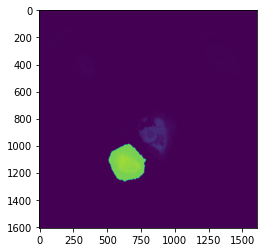

2


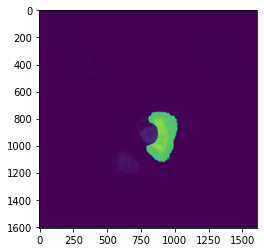

3


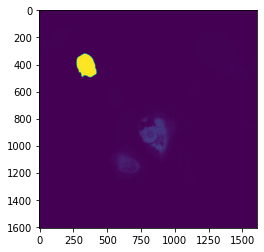

4


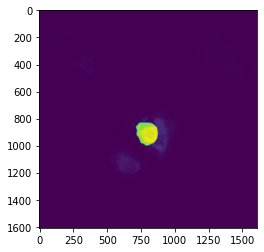

5


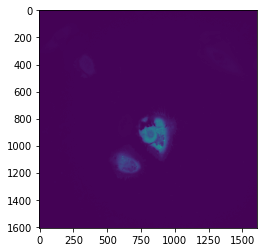

20240815_cy_plate4xy56
1


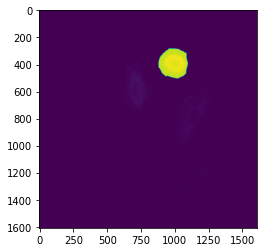

2


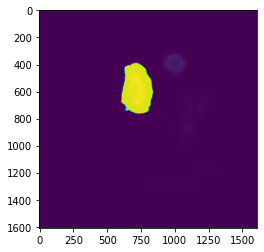

3


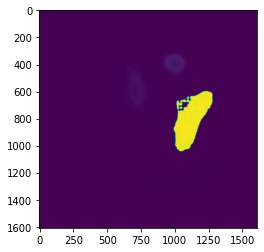

4


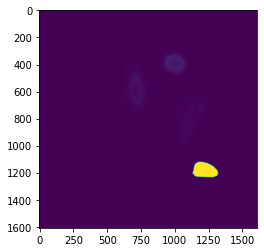

5


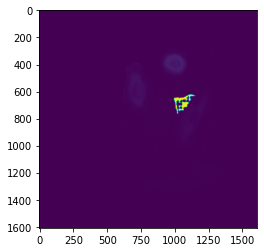

6


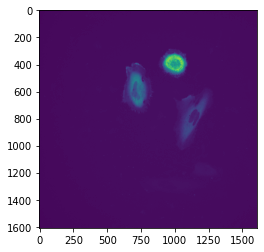

20240815_cy_plate4xy58
1


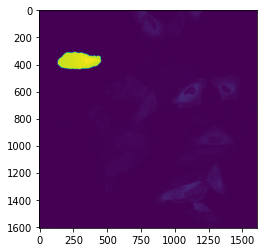

2


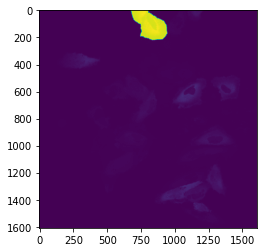

3


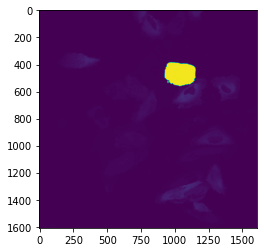

4


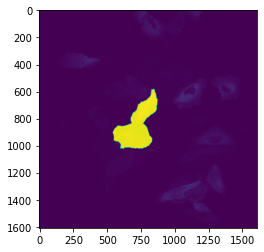

5


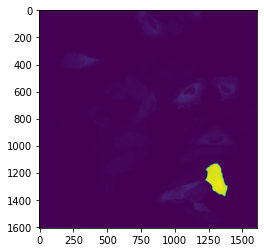

6


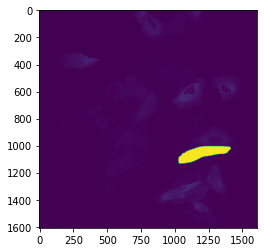

7


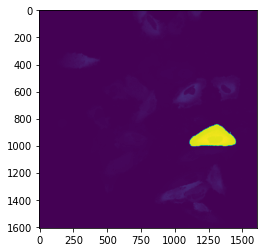

8


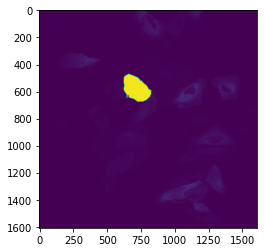

9


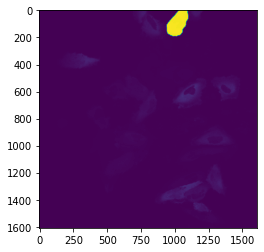

10


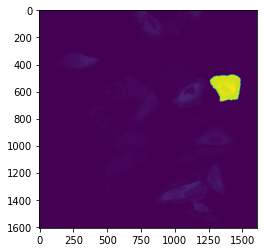

11


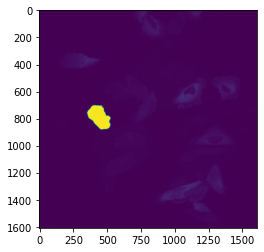

12


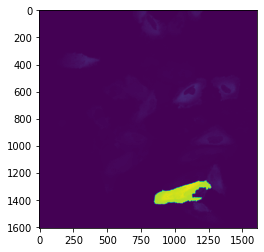

13


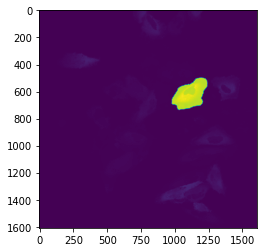

14


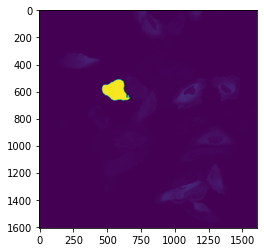

15


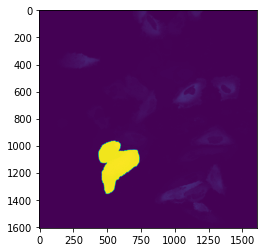

16


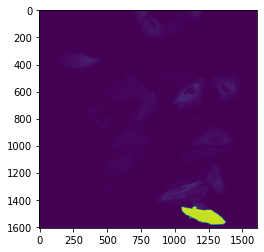

17


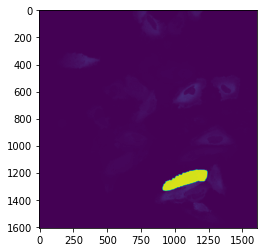

18


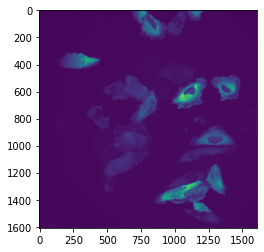

20


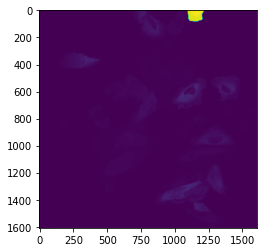

21


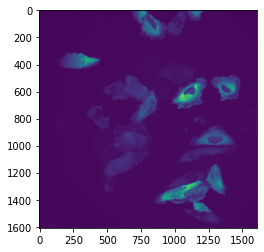

In [24]:
t = 35
for path in path_ls:
    fid = path.split('.')[0].split('/')[-1]
    print(fid)
    dcl_ob = load_data_local(f"./spark_examples/{fid}.zip")
    y_clean = dcl_ob['y'][:,:,:,0]
    arr =  dcl_ob['X'][:,:,:,0]
    t = 35
    for cellid in np.unique(y_clean[t]) :
        print(cellid+1)
        plt.imshow((y_clean[t]==(cellid+1))*2000+ arr[t,:,:]*0.1 )
        plt.show()

---
## SPARK Reporter Signal Quantification

This section implements the SPARK signal quantification method following published protocols:

1. **Puncta segmentation** – Otsu / local-threshold to separate punctate signal from diffuse whole-cell fluorescence.
2. **Whole-cell mask** – derived from the tracked cell segmentation masks produced above (`y_old_tracked`).
3. **SPARK signal** = Σ(puncta pixel intensities) / Σ(whole-cell pixel intensities) per cell per frame.
4. **Normalisation** – optionally normalise each cell's SPARK signal to a reference time-point (e.g. 120 min post-CCCP) or to the mean of a control condition (e.g. DMSO).

> Reference: PINK1-SPARK puncta quantification adapted from Bharat et al. / McWilliams et al. protocols (Analyze Particle / Trainable Weka Segmentation equivalent in Python via `skimage`).

In [13]:
def quantify_spark(
    arr: np.ndarray,
    tracked_masks: np.ndarray,
    threshold_str: str,
    cell_id: int               = None,
    minutes_per_frame: float   = 4.0,
    frame_offset_min: float    = 0.0,
    min_puncta_size: int       = 2,
    max_puncta_size: int       = 2000,
) -> pd.DataFrame:
    """
    Quantify SPARK puncta signal from a timelapse array.

    Parameters
    ----------
    arr : np.ndarray, shape (T, X, Y)
        Raw fluorescence image stack.
    tracked_masks : np.ndarray, shape (T, X, Y)
        Integer cell label masks, 0 = background.
    threshold_str : str
        Piecewise threshold definition in 1-indexed format.
        Example: '1-43:903;44-61:805'
        Ranges are inclusive on both ends and converted to 0-indexed internally.
    cell_id : int, optional
        If provided, only quantify this specific cell label.
        If None, quantify all cells in the FOV.
    minutes_per_frame : float
        Acquisition interval in minutes.
    frame_offset_min : float
        Time offset of frame 0 in minutes.
    min_puncta_size : int
        Minimum puncta size in pixels (removes single-pixel noise).
    max_puncta_size : int
        Maximum puncta size in pixels (removes whole-cell false positives).

    Returns
    -------
    pd.DataFrame with columns:
        frame, time_min, cell_id, threshold, cell_area_px, cell_total_int,
        cell_mean_int, puncta_count, puncta_area_px, puncta_total_int, spark_signal
    """
    import numpy as np
    import pandas as pd
    from skimage import measure
    from skimage.morphology import remove_small_objects
    from tqdm import tqdm

    # ── parse threshold string → per-frame threshold array (0-indexed) ────────
    def parse_thresholds(s: str, n_frames: int) -> np.ndarray:
        thresh_arr = np.full(n_frames, np.nan)
        sep = ';' if ';' in s else ','
        print(f'    [parse] sep={sep!r}  segments={s.strip().split(sep)}')  # DEBUG
        for segment in s.strip().split(sep):
            segment = segment.strip()
            print(f'    [parse] segment={segment!r}  split={segment.split(":")}')  # DEBUG
            if not segment:
                continue
            range_part, thresh_part = segment.split(':', maxsplit=1)
            thresh_val = float(thresh_part.strip())
            start_1, end_1 = range_part.strip().split('-')
            start_0 = max(0, int(start_1) - 1)
            end_0   = min(n_frames - 1, int(end_1) - 1)
            thresh_arr[start_0 : end_0 + 1] = thresh_val
        unassigned = np.where(np.isnan(thresh_arr))[0]
        if len(unassigned):
            raise ValueError(
                f'Threshold not defined for 0-indexed frames: {unassigned.tolist()}. '
                f'Check threshold string covers all {n_frames} frames.'
            )
        return thresh_arr

    n_frames   = arr.shape[0]
    thresh_arr = parse_thresholds(threshold_str, n_frames)

    # ── validate cell_id exists in at least one frame ─────────────────────────
    if cell_id is not None:
        all_ids = np.unique(tracked_masks)
        if cell_id not in all_ids:
            raise ValueError(
                f'cell_id={cell_id} not found in any frame of tracked_masks. '
                f'Available IDs: {sorted(all_ids[all_ids != 0].tolist())}'
            )

    # ── print run config ──────────────────────────────────────────────────────
    target_str = f'cell {cell_id} only' if cell_id is not None else 'all cells'
    print(f'Quantifying: {target_str}')
    print('Threshold schedule (0-indexed frames):')
    current_thresh, seg_start = None, 0
    for t in range(n_frames):
        if thresh_arr[t] != current_thresh:
            if current_thresh is not None:
                print(f'  frames {seg_start:3d}–{t-1:3d}  '
                      f'(1-idx {seg_start+1}–{t})  '
                      f'threshold >= {current_thresh:.0f}')
            current_thresh = thresh_arr[t]
            seg_start      = t
    print(f'  frames {seg_start:3d}–{n_frames-1:3d}  '
          f'(1-idx {seg_start+1}–{n_frames})  '
          f'threshold >= {current_thresh:.0f}')
    print()

    # ── main quantification loop ──────────────────────────────────────────────
    records = []

    for t in tqdm(range(n_frames), desc='Quantifying SPARK signal'):
        frame_img   = arr[t].astype(np.float32)
        label_frame = tracked_masks[t]
        thresh      = thresh_arr[t]

        # select cells to process this frame
        if cell_id is not None:
            cell_ids = np.array([cell_id]) if cell_id in label_frame else np.array([])
        else:
            cell_ids = np.unique(label_frame)
            cell_ids = cell_ids[cell_ids != 0]

        for cid in cell_ids:
            cell_mask  = (label_frame == cid)
            cell_px    = frame_img[cell_mask]

            if cell_px.size == 0:
                continue

            cell_total = float(cell_px.sum())
            cell_area  = int(cell_mask.sum())
            cell_mean  = float(cell_px.mean())

            # puncta: pixels >= threshold within cell mask
            puncta_mask = (frame_img >= thresh) & cell_mask
            puncta_mask = remove_small_objects(
                puncta_mask, min_size=min_puncta_size
            )

            # remove oversized objects
            puncta_labeled = measure.label(puncta_mask)
            for r in measure.regionprops(puncta_labeled):
                if r.area > max_puncta_size:
                    puncta_mask[puncta_labeled == r.label] = False

            puncta_labeled    = measure.label(puncta_mask)
            puncta_total      = float(frame_img[puncta_mask].sum())
            puncta_count      = int(puncta_labeled.max())
            puncta_area       = int(puncta_mask.sum())
            spark_signal      = (puncta_total / cell_total
                                 if cell_total > 0 else np.nan)

            records.append({
                'frame':            t,
                'time_min':         frame_offset_min + t * minutes_per_frame,
                'cell_id':          int(cid),
                'threshold':        thresh,
                'cell_area_px':     cell_area,
                'cell_total_int':   cell_total,
                'cell_mean_int':    cell_mean,
                'puncta_count':     puncta_count,
                'puncta_area_px':   puncta_area,
                'puncta_total_int': puncta_total,
                'spark_signal':     spark_signal,
            })

    df_spark = pd.DataFrame(records)

    print(f'Done. {len(df_spark)} rows | '
          f'{df_spark.cell_id.nunique()} cell(s) | '
          f'{n_frames} frames')

    return df_spark

In [26]:
# ── QUANT_TABLE: corrected FOV/condition/reporter annotations ─────────────────
QUANT_TABLE = [
    # ── IKK-SPK-novel / polyIC ────────────────────────────────────────────────
    {'fov': '20240822_cy_plate2c1xy48', 'cell_id': 3,
     'thresh': '1-43:903,44-61:805',
     'condition': 'polyIC', 'reporter': 'IKK-SPK-novel',
     'minutes_per_frame': 4.0},
    {'fov': '20240822_cy_plate2c1xy50', 'cell_id': 4,
     'thresh': '1-10:589,11-21:526,22-33:440,34-61:388',
     'condition': 'polyIC', 'reporter': 'IKK-SPK-novel',
     'minutes_per_frame': 4.0},
    {'fov': '20240815_cy_plate4xy55',   'cell_id': 1,
     'thresh': '1-26:2547,27-33:2030,34-81:2273',
     'condition': 'polyIC', 'reporter': 'IKK-SPK-novel',
     'minutes_per_frame': 3.0},
    {'fov': '20240815_cy_plate4xy56',   'cell_id': 2,
     'thresh': '1-43:1377,44-60:1175,61-68:1169,69-81:1068',
     'condition': 'polyIC', 'reporter': 'IKK-SPK-novel',
     'minutes_per_frame': 3.0},
    {'fov': '20240815_cy_plate4xy58',   'cell_id': 2,
     'thresh': '1-57:1623,58-65:1306,66-81:1113',
     'condition': 'polyIC', 'reporter': 'IKK-SPK-novel',
     'minutes_per_frame': 3.0},
    {'fov': '20240815_cy_plate4xy58',   'cell_id': 12,
     'thresh': '1-54:2870,55-81:2428',
     'condition': 'polyIC', 'reporter': 'IKK-SPK-novel',
     'minutes_per_frame': 3.0},
    # ── TBK1-SPK-novel / diABZI ──────────────────────────────────────────────
    {'fov': '20250126-plate1001c1xy49', 'cell_id': 2,
     'thresh': '1-49:22930',
     'condition': 'diABZI', 'reporter': 'TBK1-SPK-novel',
     'minutes_per_frame': 5.0},
    {'fov': '20250126-plate1001c1xy49', 'cell_id': 9,
     'thresh': '1-49:22930',
     'condition': 'diABZI', 'reporter': 'TBK1-SPK-novel',
     'minutes_per_frame': 5.0},
    {'fov': '20250126-plate1001c1xy54', 'cell_id': 2,
     'thresh': '1-49:3567',
     'condition': 'diABZI', 'reporter': 'TBK1-SPK-novel',
     'minutes_per_frame': 5.0},
    {'fov': '20250126-plate1001c1xy54', 'cell_id': 1,
     'thresh': '1-11:4170,12-34:3899,35-49:3318',
     'condition': 'diABZI', 'reporter': 'TBK1-SPK-novel',
     'minutes_per_frame': 5.0},
]

# ── runner ────────────────────────────────────────────────────────────────────
all_results = []

fov_groups = {}
for entry in QUANT_TABLE:
    fov_groups.setdefault(entry['fov'], []).append(entry)

for fov, entries in fov_groups.items():
    print(f'\n{"─"*70}')
    print(f'Loading: {fov}')
    dcl_ob            = load_data_local(f"./spark_examples/{fov}.zip")
    tracked_masks_fov = dcl_ob['y'][:, :, :, 0]
    arr_fov           = dcl_ob['X'][:, :, :, 0]
    print(f'  n_frames={arr_fov.shape[0]}  shape={arr_fov.shape}')

    for entry in entries:
        cid      = entry['cell_id']
        thresh   = entry['thresh']
        mpf      = entry['minutes_per_frame']
        cond     = entry['condition']
        reporter = entry['reporter']
        label    = f'{fov}  cell {cid}  [{reporter} / {cond}]'

        print(f'  → cell {cid}  ({reporter} / {cond})')
        df = quantify_spark(
            arr               = arr_fov,
            tracked_masks     = tracked_masks_fov,
            threshold_str     = thresh,
            cell_id           = cid,
            minutes_per_frame = mpf,
            frame_offset_min  = 0.0,
        )
        df['fov']      = fov
        df['condition'] = cond
        df['reporter']  = reporter
        df['label']     = label
        all_results.append({'label': label, 'df': df})

        print(df[['frame', 'time_min', 'threshold',
                  'puncta_count', 'puncta_area_px',
                  'spark_signal']].to_string(index=False))

df_combined = pd.concat([r['df'] for r in all_results], ignore_index=True)


In [27]:
SAVE_DIR = '.'
print(f'\nCombined: {len(df_combined)} rows  |  '
      f'{df_combined[["fov","cell_id"]].drop_duplicates().shape[0]} cells')
print(df_combined.groupby(['reporter','condition','fov'])['cell_id']
      .nunique().reset_index()
      .rename(columns={'cell_id':'n_cells'}).to_string(index=False))

# ── save per reporter/condition ───────────────────────────────────────────────
MANUAL_CSV = {
    ('IKK-SPK-novel',  'polyIC'): os.path.join(SAVE_DIR, 'ikk_novel_polyIC_manual.csv'),
    ('TBK1-SPK-novel', 'diABZI'): os.path.join(SAVE_DIR, 'tbk1_novel_diABZI_manual.csv'),
}

def subtract_frame0(grp):
    f0_val = grp.loc[grp['frame'] == grp['frame'].min(),
                     'spark_signal'].values
    f0_val = float(f0_val[0]) if len(f0_val) > 0 else 0.0
    grp = grp.copy()
    grp['spark_delta'] = grp['spark_signal'] - f0_val
    return grp

for (reporter, cond), path in MANUAL_CSV.items():
    sub = df_combined[
        (df_combined['reporter'] == reporter) &
        (df_combined['condition'] == cond)
    ].copy()
    sub = (sub.groupby(['fov', 'cell_id'], group_keys=False)
              .apply(subtract_frame0))
    sub.to_csv(path, index=False)
    n_cells = sub[['fov', 'cell_id']].drop_duplicates().shape[0]
    print(f'Saved {reporter} / {cond}: {path}  ({n_cells} cells, {len(sub)} rows)')


Combined: 630 rows  |  10 cells
      reporter condition                      fov  n_cells
 IKK-SPK-novel    polyIC   20240815_cy_plate4xy55        1
 IKK-SPK-novel    polyIC   20240815_cy_plate4xy56        1
 IKK-SPK-novel    polyIC   20240815_cy_plate4xy58        2
 IKK-SPK-novel    polyIC 20240822_cy_plate2c1xy48        1
 IKK-SPK-novel    polyIC 20240822_cy_plate2c1xy50        1
TBK1-SPK-novel    diABZI 20250126-plate1001c1xy49        2
TBK1-SPK-novel    diABZI 20250126-plate1001c1xy54        2
Saved IKK-SPK-novel / polyIC: ./ikk_novel_polyIC_manual.csv  (6 cells, 435 rows)
Saved TBK1-SPK-novel / diABZI: ./tbk1_novel_diABZI_manual.csv  (4 cells, 195 rows)


label                                                         n_frames   t_min   t_max
-------------------------------------------------------------------------------------
20240822_cy_plate2c1xy48  cell 3  [IKK-SPK-novel / polyIC]          61     0.0   240.0
20240822_cy_plate2c1xy50  cell 4  [IKK-SPK-novel / polyIC]          59     0.0   240.0
20240815_cy_plate4xy55  cell 1  [IKK-SPK-novel / polyIC]            81     0.0   240.0
20240815_cy_plate4xy56  cell 2  [IKK-SPK-novel / polyIC]            81     0.0   240.0
20240815_cy_plate4xy58  cell 2  [IKK-SPK-novel / polyIC]            80     0.0   240.0
20240815_cy_plate4xy58  cell 12  [IKK-SPK-novel / polyIC]           73     0.0   216.0
20250126-plate1001c1xy49  cell 2  [TBK1-SPK-novel / diABZI]         49     0.0   240.0
20250126-plate1001c1xy49  cell 9  [TBK1-SPK-novel / diABZI]         49     0.0   240.0
20250126-plate1001c1xy54  cell 2  [TBK1-SPK-novel / diABZI]         49     0.0   240.0
20250126-plate1001c1xy54  cell 1  [TBK1-SPK-

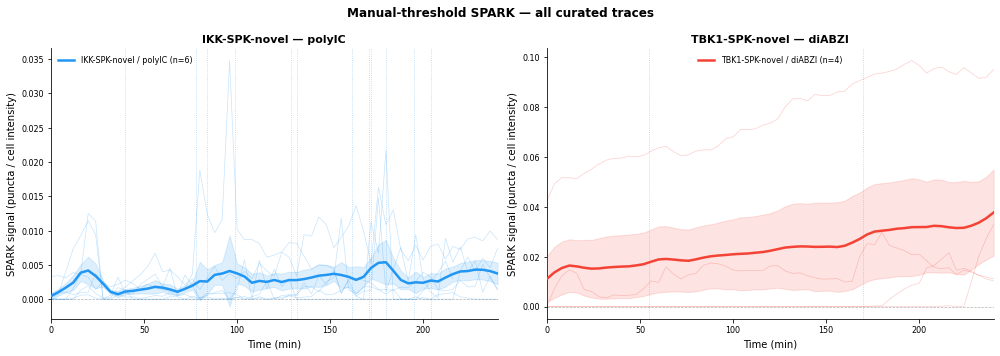


Combined: 630 rows  |  10 cells
      reporter condition                      fov  n_cells
 IKK-SPK-novel    polyIC   20240815_cy_plate4xy55        1
 IKK-SPK-novel    polyIC   20240815_cy_plate4xy56        1
 IKK-SPK-novel    polyIC   20240815_cy_plate4xy58        2
 IKK-SPK-novel    polyIC 20240822_cy_plate2c1xy48        1
 IKK-SPK-novel    polyIC 20240822_cy_plate2c1xy50        1
TBK1-SPK-novel    diABZI 20250126-plate1001c1xy49        2
TBK1-SPK-novel    diABZI 20250126-plate1001c1xy54        2


In [29]:
# ── verify all traces end at 240 min ─────────────────────────────────────────
COMMON_TIME = np.linspace(0, 240, 61)   # 4-min reference grid, 0–240 min
print(f'{"label":<60}  {"n_frames":>8}  {"t_min":>6}  {"t_max":>6}')
print('-' * 85)
for entry in all_results:
    df    = entry['df']
    label = entry['label']
    print(f'{label:<60}  '
          f'{len(df):>8}  '
          f'{df["time_min"].min():>6.1f}  '
          f'{df["time_min"].max():>6.1f}')

# ── colour scheme: one colour per (reporter, condition) group ─────────────────
GROUP_COLORS = {
    ('IKK-SPK-novel',  'polyIC'): '#2196F3',
    ('TBK1-SPK-novel', 'diABZI'): '#F44336',
}

# ── overlay plot — two panels, one per reporter/condition group ───────────────
groups = df_combined.groupby(['reporter', 'condition'])

fig, axes = plt.subplots(1, len(groups), figsize=(7 * len(groups), 5),
                          sharey=False)
if len(groups) == 1:
    axes = [axes]

for ax, ((reporter, cond), _) in zip(axes, groups):
    color     = GROUP_COLORS.get((reporter, cond), '#333333')
    ax_traces = [r for r in all_results
                 if r['df']['reporter'].iloc[0] == reporter
                 and r['df']['condition'].iloc[0] == cond]

    trace_mat = []
    for entry in ax_traces:
        df  = entry['df']
        sig = df['spark_signal'].values
        t   = df['time_min'].values

        # resample to COMMON_TIME so all traces are on the same grid
        tr = np.full(61, np.nan)
        t_min, t_max = t.min(), t.max()
        mask = (COMMON_TIME >= t_min) & (COMMON_TIME <= t_max)
        if mask.sum() >= 2:
            tr[mask] = np.interp(COMMON_TIME[mask], t, sig)
        trace_mat.append(tr)

        # individual raw trace
        ax.plot(COMMON_TIME, tr, color=color, lw=0.7, alpha=0.25)

        # mark threshold change points
        thresh_vals = df['threshold'].values
        for i in range(1, len(thresh_vals)):
            if thresh_vals[i] != thresh_vals[i - 1]:
                ax.axvline(t[i], color=color, lw=0.8, ls=':', alpha=0.4)

    # mean ± SEM fitted line
    if trace_mat:
        mat      = np.array(trace_mat)
        n_obs    = np.sum(~np.isnan(mat), axis=0).clip(1)
        coverage = n_obs / mat.shape[0]
        mean_t   = np.nanmean(mat, axis=0)
        sem      = np.nanstd(mat, axis=0) / np.sqrt(n_obs)

        good   = coverage >= 0.5
        mean_m = np.where(good, mean_t, np.nan)
        sem_m  = np.where(good, sem,    np.nan)

        fitted = np.full_like(mean_m, np.nan)
        valid  = ~np.isnan(mean_m)
        if valid.sum() > 7:
            fitted[valid] = savgol_filter(mean_m[valid],
                                          window_length=7, polyorder=2)
        else:
            fitted = mean_m

        ax.plot(COMMON_TIME, fitted, color=color, lw=2.5, zorder=5,
                label=f'{reporter} / {cond} (n={mat.shape[0]})')
        ax.fill_between(COMMON_TIME, fitted - sem_m, fitted + sem_m,
                        color=color, alpha=0.15, zorder=4)
        ax.plot(COMMON_TIME[~good], fitted[~good],
                color=color, lw=1.5, ls=':', zorder=4, alpha=0.5)

    ax.axhline(0, color='black', lw=0.7, ls='--', alpha=0.3)
    ax.set_xlabel('Time (min)', fontsize=10)
    ax.set_ylabel('SPARK signal (puncta / cell intensity)', fontsize=10)
    ax.set_title(f'{reporter} — {cond}', fontsize=11, fontweight='bold')
    ax.set_xlim(0, 240)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(fontsize=8, frameon=False)
    ax.tick_params(labelsize=8)

fig.suptitle('Manual-threshold SPARK — all curated traces',
             fontsize=12, fontweight='bold')
fig.tight_layout()
plt.show()

# ── combined dataframe ────────────────────────────────────────────────────────
df_combined = pd.concat([r['df'] for r in all_results], ignore_index=True)
print(f'\nCombined: {len(df_combined)} rows  |  '
      f'{df_combined[["fov","cell_id"]].drop_duplicates().shape[0]} cells')
print(df_combined.groupby(['reporter', 'condition', 'fov'])['cell_id']
      .nunique().reset_index()
      .rename(columns={'cell_id': 'n_cells'}).to_string(index=False))